In [1]:
from pathlib import Path
import math
import pickle
import warnings

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

# Select datasets and metrics to display.
DATASETS = ['heart', 'diabetes_h', 'diabetes_130', 'obesity', 'obesity_bin', 'breast_cancer']
METRICS = {
    'accuracy': 'Accuracy',
    'f1': 'F1 score',
    'roc_auc': 'ROC-AUC',
}

# Run from the project root or from src/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'results_metrics').is_dir() and (PROJECT_ROOT.parent / 'results_metrics').is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
RESULTS_DIR = PROJECT_ROOT / 'results_metrics' / 'current'

# Expected sizes keep missing intermediate results visible as gaps.
DATASET_SIZES = {
    'heart': [100, 500, 1000, 5000, 10000],
    'diabetes_h': [100, 500, 1000, 5000, 10000],
    'diabetes_130': [100, 500, 1000, 5000, 10000],
    'obesity': [100, 500, 1000, 1688],
    'obesity_bin': [100, 500, 1000, 1688],
    'breast_cancer': [100, 455],
}
DATASET_LABELS = {
    'heart': 'Heart', 'diabetes_h': 'Diabetes-H',
    'diabetes_130': 'Diabetes-130', 'obesity': 'Obesity',
    'obesity_bin': 'Obesity-Bin', 'breast_cancer': 'Breast Cancer',
}
MODEL_STYLES = {
    'lr':       {'label': 'LR',           'color': '#0072B2', 'marker': 'o'},
    'rf':       {'label': 'RF',           'color': '#D55E00', 'marker': 's'},
    'mlp':      {'label': 'MLP',          'color': '#009E73', 'marker': '^'},
    'nam':      {'label': 'NAM',          'color': '#CC79A7', 'marker': 'D'},
    'kan':      {'label': 'Logistic-KAN', 'color': '#E69F00', 'marker': 'v'},
    'kan_gam':  {'label': 'KAAM',         'color': '#332288', 'marker': 'P'},
    'ebm':      {'label': 'EBM',          'color': '#882255', 'marker': 'X'},
    'xgboost':  {'label': 'XGBoost',      'color': '#44AA99', 'marker': '<'},
    'lightgbm': {'label': 'LightGBM',     'color': '#999933', 'marker': '>'},
}
MODELS = list(MODEL_STYLES)  # Replace with a subset if desired.

# Paper-sized figures (inches and points).
FIGURE_WIDTH = 7.0
PANEL_HEIGHT = 2.7
MAX_COLUMNS = 2
FONT_SIZE = 9
TITLE_SIZE = 10
LEGEND_SIZE = 8
LINE_WIDTH = 1.3
MARKER_SIZE = 4
BAND_ALPHA = 0.16
X_SCALE = 'log'
SAVE_FIGURES = False
OUTPUT_DIR = PROJECT_ROOT / 'results_metrics' / 'figures'
OUTPUT_FORMAT = 'pdf'


# Sample-size analysis

The horizontal axis is the size of the selected training and validation set. The held-out test set is excluded. Each shaded band represents a saved 95% bootstrap interval; no model is trained and no metric is recalculated here.

Choose the datasets, metrics and visual styles in the first cell. Set `METRICS` to include `error_rate` if the desired quantity is `1 - accuracy`. Only load trusted pickle files.


In [2]:
if not METRICS:
    raise ValueError('Select at least one metric in METRICS.')
if not RESULTS_DIR.is_dir():
    raise FileNotFoundError(f'Results directory not found: {RESULTS_DIR}')

unknown_datasets = set(DATASETS) - DATASET_SIZES.keys()
unknown_models = set(MODELS) - MODEL_STYLES.keys()
if unknown_datasets or unknown_models:
    raise ValueError(f'Unknown datasets: {unknown_datasets}; unknown models: {unknown_models}')

rows = []
missing = []
for dataset in DATASETS:
    for size in DATASET_SIZES[dataset]:
        for model in MODELS:
            path = RESULTS_DIR / str(size) / dataset / f'{model}.pkl'
            if not path.is_file():
                missing.append(f'{dataset}, N={size}, {model}: file not found')
                continue
            with path.open('rb') as file:
                result = pickle.load(file)
            means = result.get('metric_mean', {})
            intervals = result.get('metric_ci', {})
            is_95_percent = result.get('bootstrap', {}).get('ci') == 95
            for metric in METRICS:
                stored_metric = 'accuracy' if metric == 'error_rate' else metric
                if stored_metric not in means:
                    missing.append(f'{dataset}, N={size}, {model}: {metric} not found')
                    continue
                value = float(means[stored_metric])
                lower, upper = np.nan, np.nan
                if is_95_percent and stored_metric in intervals:
                    lower, upper = map(float, intervals[stored_metric])
                else:
                    missing.append(f'{dataset}, N={size}, {model}: 95% CI for {metric} not found')
                if metric == 'error_rate':
                    value, lower, upper = 1 - value, 1 - upper, 1 - lower
                rows.append({
                    'dataset': dataset, 'size': int(size), 'model': model,
                    'metric': metric, 'mean': value, 'lower': lower, 'upper': upper,
                })

results = pd.DataFrame(rows, columns=['dataset', 'size', 'model', 'metric', 'mean', 'lower', 'upper'])
if missing:
    print(f'Missing results or intervals ({len(missing)}):')
    for message in missing:
        print(f'  - {message}')
if results.empty:
    print('No matching metrics found. Check the configuration and results directory.')
else:
    print(f'Loaded {len(results)} metric values from {RESULTS_DIR}')


Loaded 675 metric values from C:\Users\Alex\CODE\classification_with_kans\results_metrics\current


## Figures

Each model uses the same color and marker across panels and datasets. Lines and confidence bands are interrupted at missing sizes. A point without a saved 95% interval is still shown, without a band at that size.


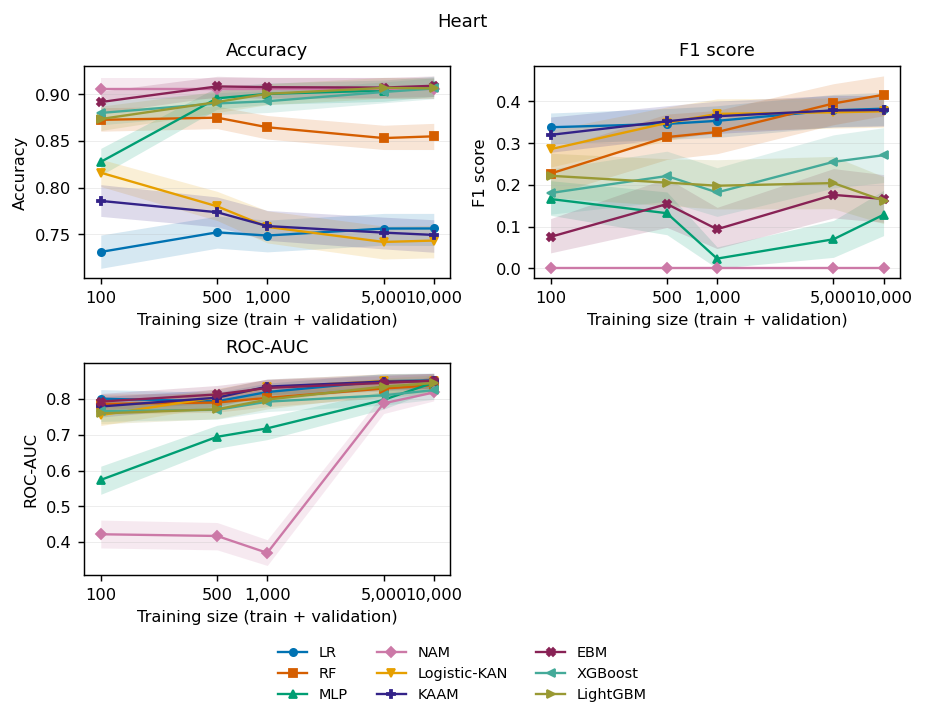

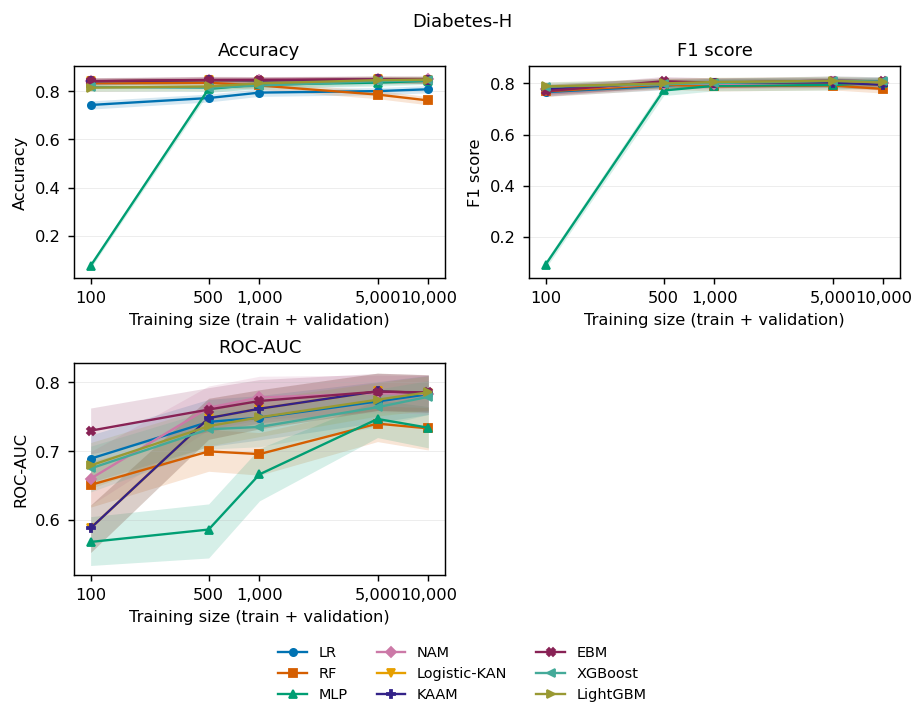

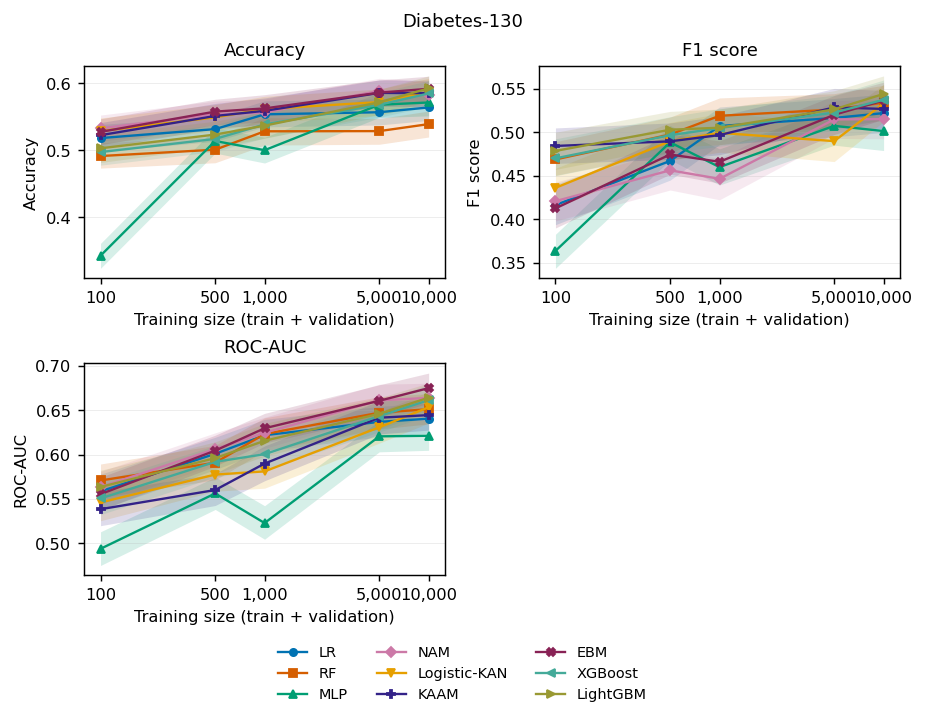

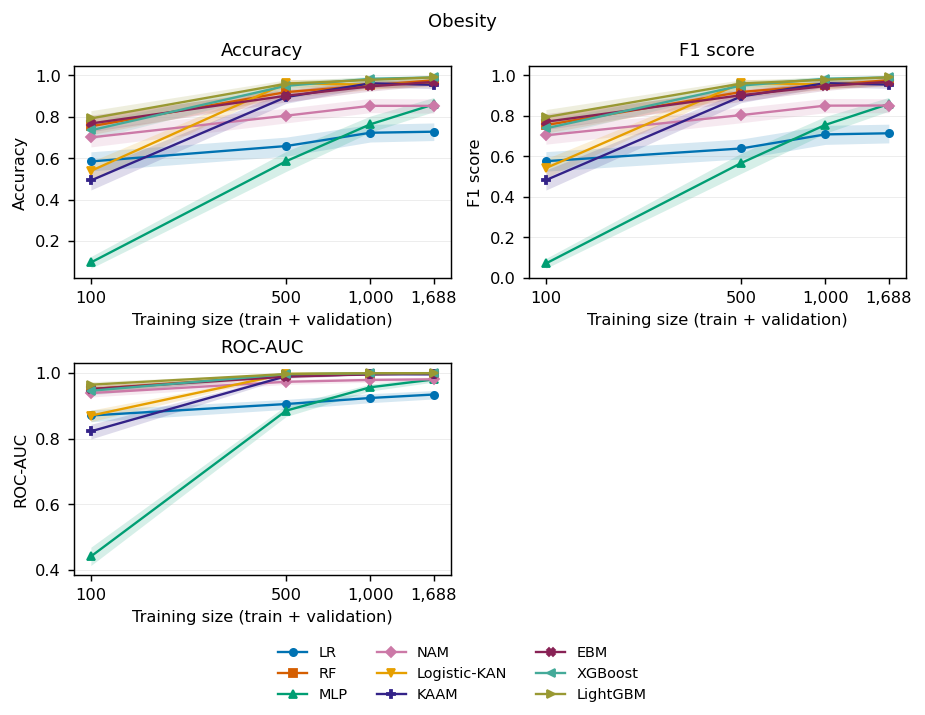

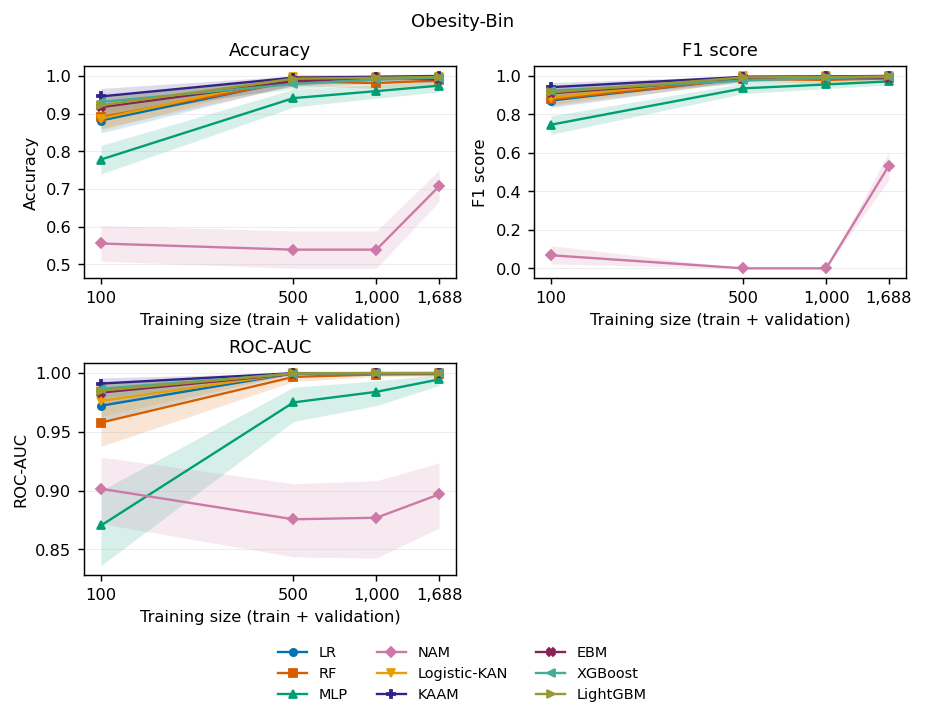

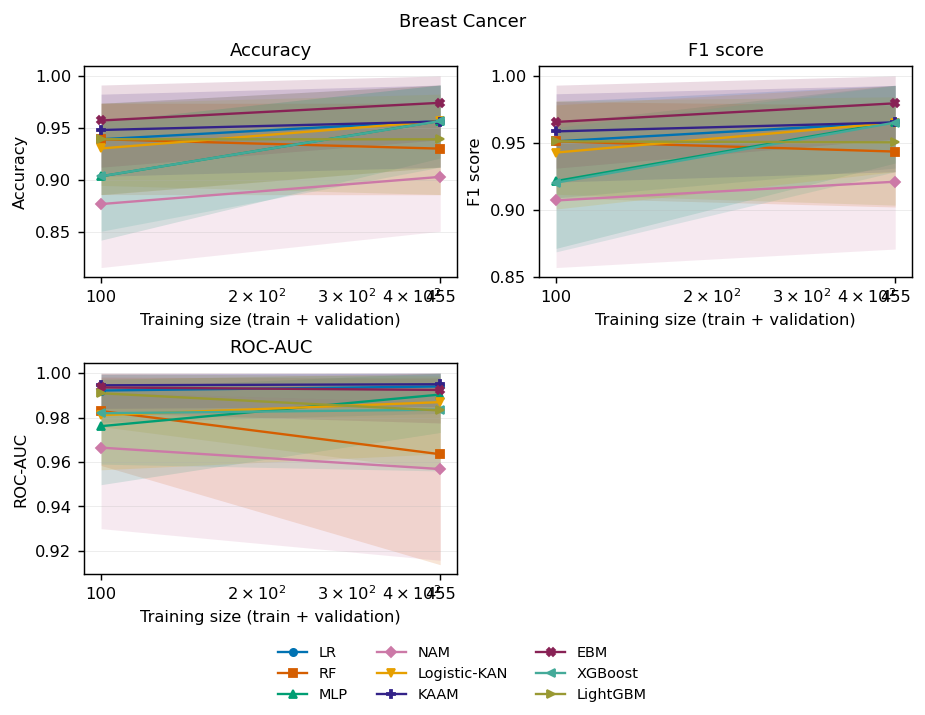

In [3]:
plot_style = {
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
    'figure.facecolor': 'white', 'savefig.facecolor': 'white',
    'axes.facecolor': 'white', 'axes.edgecolor': 'black', 'axes.labelcolor': 'black',
    'text.color': 'black', 'xtick.color': 'black', 'ytick.color': 'black',
    'legend.facecolor': 'white', 'legend.edgecolor': 'black',
    'font.size': FONT_SIZE,
    'axes.labelsize': FONT_SIZE,
    'axes.titlesize': TITLE_SIZE,
    'xtick.labelsize': FONT_SIZE,
    'ytick.labelsize': FONT_SIZE,
    'legend.fontsize': LEGEND_SIZE,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
}

with plt.rc_context(plot_style):
    for dataset in DATASETS:
        dataset_results = results[results['dataset'] == dataset]
        if dataset_results.empty:
            print(f'Skipping {dataset}: no selected results.')
            continue

        sizes = sorted(DATASET_SIZES[dataset])
        n_metrics = len(METRICS)
        n_cols = min(MAX_COLUMNS, n_metrics)
        n_rows = math.ceil(n_metrics / n_cols)
        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(FIGURE_WIDTH, PANEL_HEIGHT * n_rows),
            squeeze=False,
            layout='constrained',
        )
        axes = axes.ravel()
        plotted_models = set()

        for ax, (metric, metric_label) in zip(axes, METRICS.items()):
            for model in MODELS:
                points = dataset_results[
                    (dataset_results['metric'] == metric)
                    & (dataset_results['model'] == model)
                ].set_index('size').reindex(sizes)
                if points['mean'].notna().sum() == 0:
                    continue
                style = MODEL_STYLES[model]
                x = np.asarray(sizes)
                mean = points['mean'].to_numpy(dtype=float)
                lower = points['lower'].to_numpy(dtype=float)
                upper = points['upper'].to_numpy(dtype=float)
                ax.plot(
                    x, mean, color=style['color'], marker=style['marker'],
                    linewidth=LINE_WIDTH, markersize=MARKER_SIZE,
                )
                ax.fill_between(x, lower, upper, color=style['color'], alpha=BAND_ALPHA, linewidth=0)
                plotted_models.add(model)

            ax.set_title(metric_label)
            ax.set_xlabel('Training size (train + validation)')
            ax.set_ylabel(metric_label)
            ax.set_xscale(X_SCALE)
            ax.set_xticks(sizes, [f'{size:,}' for size in sizes])
            ax.tick_params(axis='x', which='minor', bottom=False)
            ax.grid(axis='y', alpha=0.25, linewidth=0.5)

        for ax in axes[n_metrics:]:
            ax.set_visible(False)

        handles = [
            Line2D(
                [0], [0], color=MODEL_STYLES[model]['color'],
                marker=MODEL_STYLES[model]['marker'], linewidth=LINE_WIDTH,
                markersize=MARKER_SIZE, label=MODEL_STYLES[model]['label'],
            )
            for model in MODELS if model in plotted_models
        ]
        if handles:
            fig.legend(handles=handles, loc='outside lower center', ncol=min(3, len(handles)), frameon=False)
        fig.suptitle(DATASET_LABELS.get(dataset, dataset), fontsize=TITLE_SIZE)

        if SAVE_FIGURES:
            OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
            output_path = OUTPUT_DIR / f'{dataset}_sample_sizes.{OUTPUT_FORMAT}'
            fig.savefig(output_path, bbox_inches='tight')
            print(f'Saved {output_path}')
        plt.show()


## Paper figure — ROC-AUC versus training size

One panel per dataset, with a common model legend. The horizontal axis is train plus internal validation size, and the vertical axis is ROC-AUC. Bands are saved 95% percentile bootstrap intervals for fixed test predictions; no models are retrained. This is a sample-size plot, not a threshold-based ROC curve.

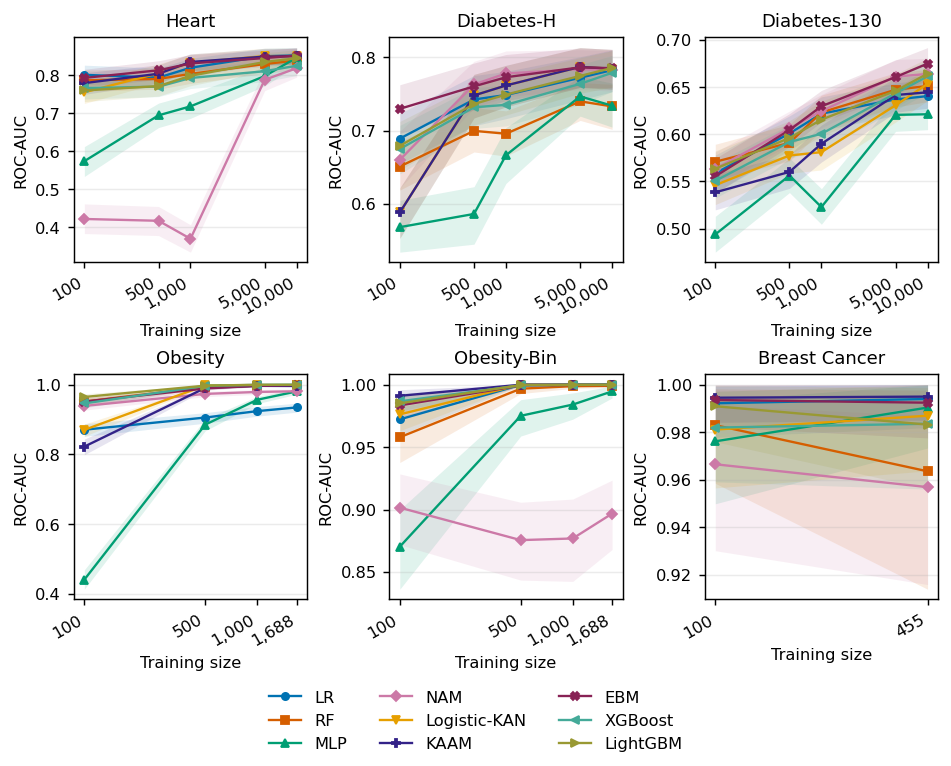

In [4]:
from matplotlib.ticker import NullLocator, NullFormatter
PAPER_METRIC = 'roc_auc'  # Any stored scalar metric, e.g. 'accuracy', 'f1', 'brier'.
PAPER_METRIC_LABEL = 'ROC-AUC'
PAPER_OUTPUT_DIR = OUTPUT_DIR / 'paper'
PAPER_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

with plt.rc_context({**plot_style, 'font.size':10, 'axes.titlesize':10, 'axes.labelsize':9, 'xtick.labelsize':9, 'ytick.labelsize':9, 'legend.fontsize':9}):
    fig_sample_size, axes = plt.subplots(2, 3, figsize=(7.2, 5.8), squeeze=False, layout='constrained')
    available_models = set()
    for ax, dataset in zip(axes.flat, DATASETS):
        sizes = DATASET_SIZES[dataset]
        for model in MODELS:
            points = []
            for size in sizes:
                path = RESULTS_DIR / str(size) / dataset / f'{model}.pkl'
                if not path.is_file():
                    points.append((np.nan, np.nan, np.nan))
                    continue
                with path.open('rb') as file:
                    saved = pickle.load(file)
                mean = saved.get('metric_mean', {}).get(PAPER_METRIC, np.nan)
                interval = saved.get('metric_ci', {}).get(PAPER_METRIC, (np.nan, np.nan))
                if saved.get('bootstrap', {}).get('ci') != 95:
                    interval = (np.nan, np.nan)
                points.append((mean, *interval))
            values = np.asarray(points, dtype=float)
            if not np.isfinite(values[:, 0]).any():
                continue
            style = MODEL_STYLES[model]
            ax.plot(sizes, values[:, 0], color=style['color'], marker=style['marker'], linewidth=1.3, markersize=4)
            ax.fill_between(sizes, values[:, 1], values[:, 2], color=style['color'], alpha=0.12, linewidth=0)
            available_models.add(model)
        ax.set_title(DATASET_LABELS[dataset])
        ax.set_xlabel('Training size')
        ax.set_ylabel(PAPER_METRIC_LABEL)
        ax.set_xscale(X_SCALE)
        ax.set_xticks(sizes, [f'{size:,}' for size in sizes], rotation=30, ha='right')
        ax.xaxis.set_minor_locator(NullLocator())
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.grid(axis='y', alpha=0.25)
    for ax in axes.flat[len(DATASETS):]:
        ax.set_visible(False)
    handles = [Line2D([0], [0], color=MODEL_STYLES[m]['color'], marker=MODEL_STYLES[m]['marker'],
                       label=MODEL_STYLES[m]['label'], linewidth=1.3, markersize=4)
               for m in MODELS if m in available_models]
    fig_sample_size.legend(handles=handles, loc='outside lower center', ncol=3, frameon=False)
    fig_sample_size.savefig(PAPER_OUTPUT_DIR / f'{PAPER_METRIC}_all_datasets.pdf', bbox_inches='tight', facecolor='white')
    fig_sample_size.savefig(PAPER_OUTPUT_DIR / f'{PAPER_METRIC}_all_datasets.png', dpi=180, bbox_inches='tight', facecolor='white')
    plt.show()

## Appendix figures — classwise calibration at N=1,000 (Breast Cancer N=455)

Each reliability curve compares the average predicted probability with the observed frequency in nonempty, equal-width bins. The diagonal represents perfect calibration. Binary curves use the saved positive class. The first six-panel figure shows a specified class for each multiclass dataset; additional figures cover the remaining classes. The class is identified within each panel. This avoids pooling distinct multiclass labels into a single calibration curve.

The accompanying ECE table uses the saved bootstrap means and intervals, including macro classwise ECE and every class-specific ECE. Reliability curves themselves use the complete held-out test predictions and have no confidence band. The calibration figures are descriptive, and neither probabilities nor operating thresholds are recalibrated using test labels.

,Dataset,Model,Metric,Bootstrap mean,Lower 95% CI,Upper 95% CI
0,Heart,LR,Positive-class ECE,0.245831,0.233172,0.258390
1,Heart,LR,Class 0 ECE,0.245831,0.233172,0.258390
2,Heart,LR,Class 1 ECE,0.245831,0.233172,0.258390
3,Heart,RF,Positive-class ECE,0.119996,0.108639,0.130973
4,Heart,RF,Class 0 ECE,0.119996,0.108639,0.130973
...,...,...,...,...,...,...
220,Breast Cancer,XGBoost,Class 0 ECE,0.049121,0.021644,0.085308
221,Breast Cancer,XGBoost,Class 1 ECE,0.049121,0.021644,0.085308
222,Breast Cancer,LightGBM,Positive-class ECE,0.061741,0.024735,0.112476
223,Breast Cancer,LightGBM,Class 0 ECE,0.061741,0.024735,0.112476


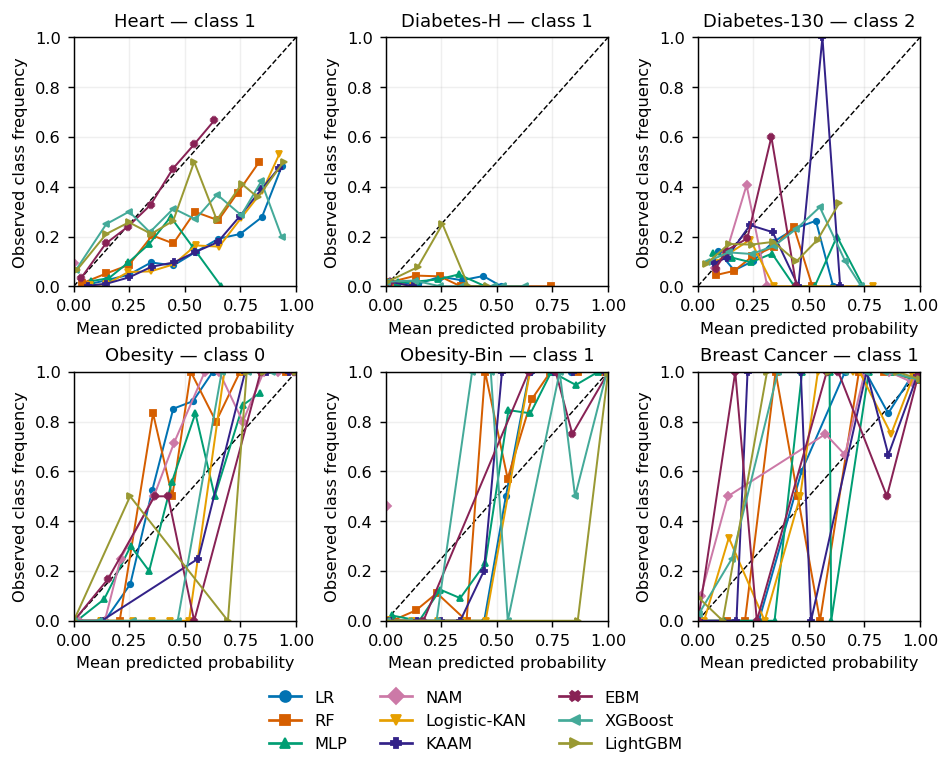

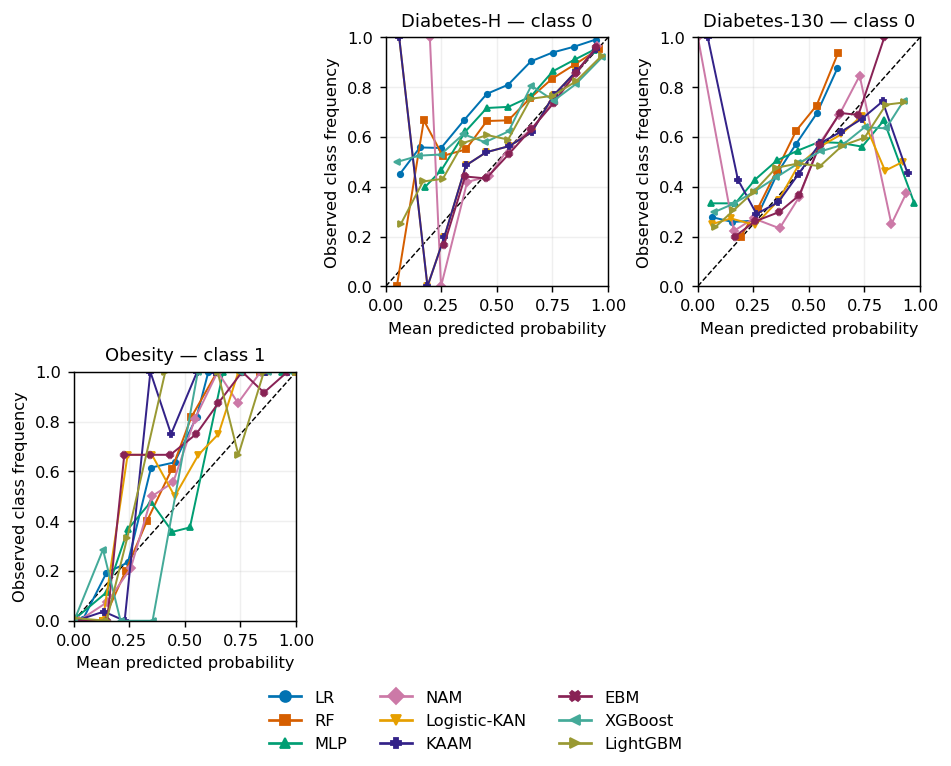

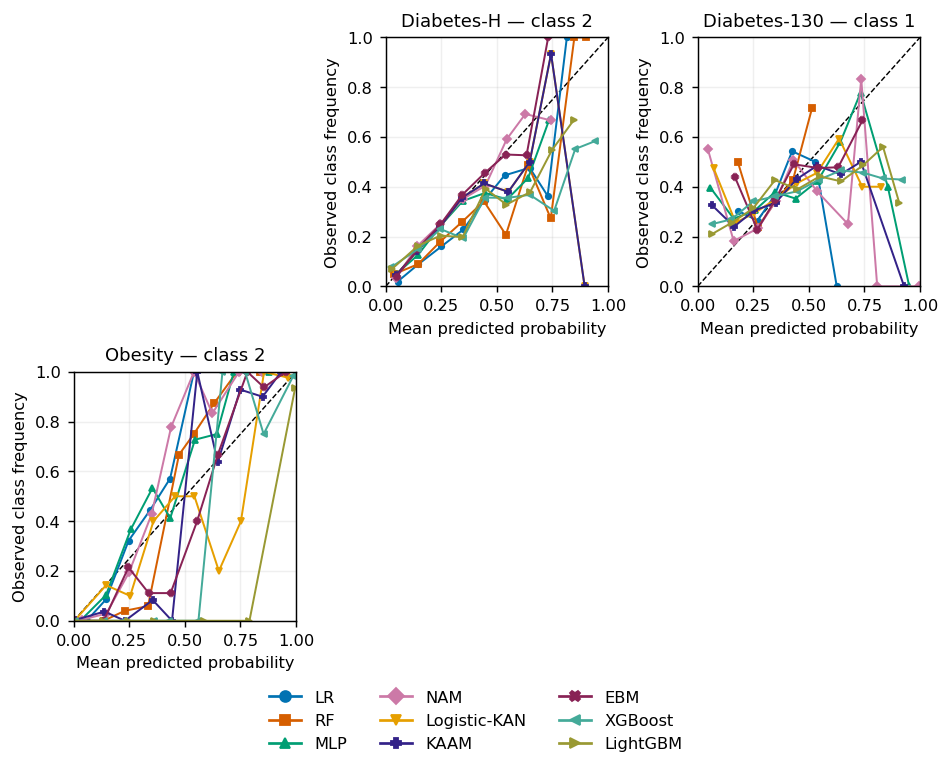

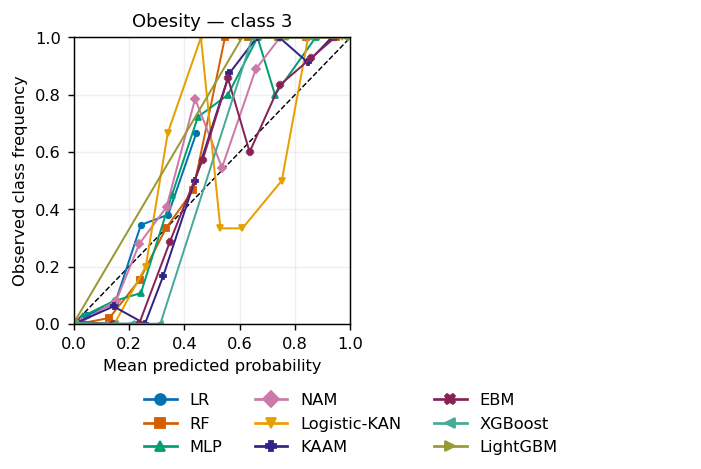

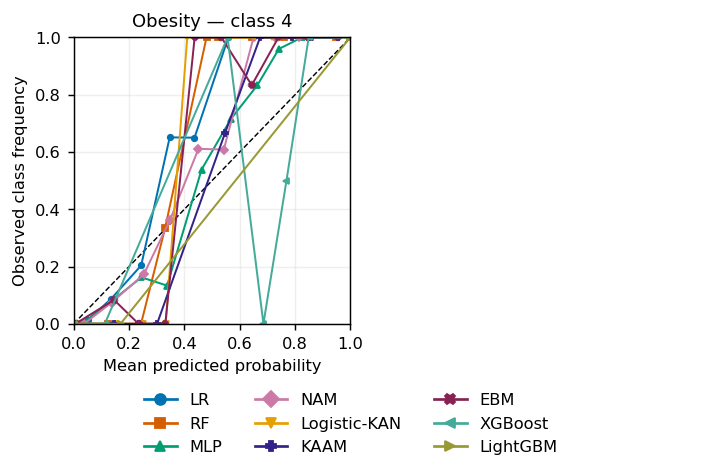

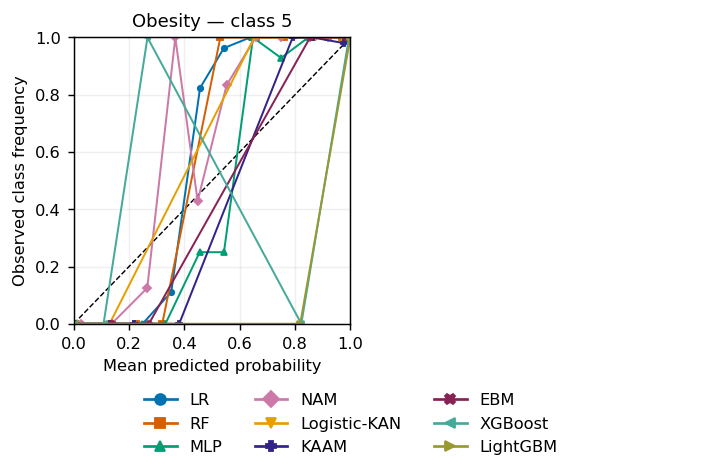

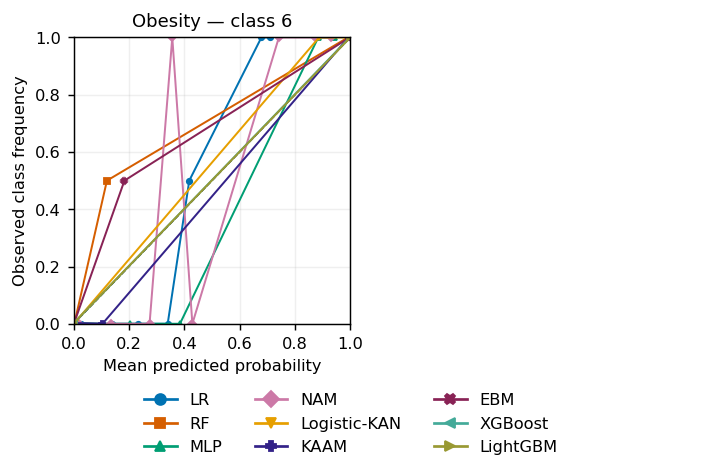

In [5]:
CALIBRATION_MODELS = MODELS  # Select fewer models if a panel is crowded.
CALIBRATION_PRIMARY_CLASS = {'diabetes_h': 1, 'diabetes_130': 2, 'obesity': 0}
CALIBRATION_ALL_CLASSES = True
CALIBRATION_BINS = 10
calibration_results, calibration_rows = {}, []
for dataset in DATASETS:
    size = 455 if dataset == 'breast_cancer' else 1000
    for model in CALIBRATION_MODELS:
        path = RESULTS_DIR / str(size) / dataset / f'{model}.pkl'
        if not path.is_file():
            print(f'Missing calibration result: {path}')
            continue
        with path.open('rb') as file:
            saved = pickle.load(file)
        classes = np.asarray(saved['classes']).reshape(-1)
        if saved.get('bootstrap', {}).get('ece_bins') != CALIBRATION_BINS:
            raise ValueError(f'ECE bin count differs from the reliability plot: {path}')
        calibration_results[(dataset, model)] = saved
        keys = [('Positive-class ECE' if len(classes) == 2 else 'Macro classwise ECE',
                 'ece' if len(classes) == 2 else 'ece_macro')]
        keys += [(f'Class {label} ECE', f'ece_class_{i}') for i, label in enumerate(classes)]
        for label, key in keys:
            mean = saved.get('metric_mean', {}).get(key)
            interval = saved.get('metric_ci', {}).get(key)
            calibration_rows.append({'Dataset': DATASET_LABELS[dataset], 'Model': MODEL_STYLES[model]['label'],
                                     'Metric': label, 'Bootstrap mean': mean,
                                     'Lower 95% CI': interval[0] if interval else np.nan,
                                     'Upper 95% CI': interval[1] if interval else np.nan})
display(pd.DataFrame(calibration_rows))

class_pages = {}
for dataset in DATASETS:
    selected = next((r for (d, _), r in calibration_results.items() if d == dataset), None)
    if selected is None:
        continue
    classes = np.asarray(selected['classes']).tolist()
    first = classes[1] if len(classes) == 2 else CALIBRATION_PRIMARY_CLASS.get(dataset, classes[0])
    if first not in classes:
        raise ValueError(f'Unknown primary calibration class for {dataset}: {first}')
    class_pages[dataset] = [first] + ([c for c in classes if c != first] if len(classes) > 2 and CALIBRATION_ALL_CLASSES else [])

def reliability_points(y_true, probability, target, n_bins):
    probability = np.asarray(probability, dtype=float)
    indices = np.minimum((probability * n_bins).astype(int), n_bins - 1)
    points = []
    for b in range(n_bins):
        mask = indices == b
        if mask.any():
            points.append((probability[mask].mean(), (np.asarray(y_true)[mask] == target).mean()))
    return np.asarray(points)

for page in range(max(map(len, class_pages.values()), default=0)):
    with plt.rc_context({**plot_style, 'font.size':10, 'axes.titlesize':10, 'axes.labelsize':9, 'xtick.labelsize':9, 'ytick.labelsize':9, 'legend.fontsize':9}):
        fig_calibration, axes = plt.subplots(2, 3, figsize=(7.2, 5.8), squeeze=False, layout='constrained')
        shown_models = set()
        for ax, dataset in zip(axes.flat, DATASETS):
            if page >= len(class_pages.get(dataset, [])):
                ax.set_visible(False)
                continue
            target = class_pages[dataset][page]
            ax.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=0.8)
            for model in CALIBRATION_MODELS:
                saved = calibration_results.get((dataset, model))
                if saved is None:
                    continue
                classes = np.asarray(saved['classes'])
                target_idx = np.flatnonzero(classes == target)
                if len(target_idx) != 1:
                    raise ValueError(f'Class {target} not found in {dataset}/{model}')
                proba = np.asarray(saved['y_proba'])
                if proba.ndim == 1:
                    proba = np.column_stack([1 - proba, proba])
                curve = reliability_points(saved['y_test'], proba[:, target_idx[0]], target, CALIBRATION_BINS)
                style = MODEL_STYLES[model]
                ax.plot(curve[:, 0], curve[:, 1], color=style['color'], marker=style['marker'], linewidth=1.1, markersize=3)
                shown_models.add(model)
            ax.set_title(f'{DATASET_LABELS[dataset]} — class {target}')
            ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Mean predicted probability', ylabel='Observed class frequency')
            ax.grid(alpha=0.2)
        for ax in axes.flat[len(DATASETS):]:
            ax.set_visible(False)
        handles = [Line2D([0], [0], color=MODEL_STYLES[m]['color'], marker=MODEL_STYLES[m]['marker'],
                           label=MODEL_STYLES[m]['label']) for m in CALIBRATION_MODELS if m in shown_models]
        fig_calibration.legend(handles=handles, loc='outside lower center', ncol=3, frameon=False)
        fig_calibration.savefig(PAPER_OUTPUT_DIR / f'calibration_classwise_panel{page + 1}.pdf', bbox_inches='tight', facecolor='white')
        fig_calibration.savefig(PAPER_OUTPUT_DIR / f'calibration_classwise_panel{page + 1}.png', dpi=180, bbox_inches='tight', facecolor='white')
        plt.show()